# 00 · 环境自检

跑一遍这个 notebook，每个格子都能出结果，就说明环境没问题，可以开始阶段 1 了。

**在 PyCharm 里**：右上角解释器选 `AI-Data/.venv/Scripts/python.exe`，然后点每个格子左边的 ▶，或者按 `Shift+Enter` 一格一格往下跑。

> 编程第一原则：**先确认环境，再写业务代码**。90% 的"代码跑不起来"其实是环境问题。

## 1. 解释器信息

重点看 `sys.executable` 是不是指向项目里的 `.venv`。
如果指向 `D:\develop\Python\python.exe`，说明你在用全局 Python，包管理迟早一团乱。

In [4]:
import platform
import sys

print("Python  :", sys.version.split()[0])
print("解释器  :", sys.executable)
print("系统    :", platform.platform())

Python  : 3.13.9
解释器  : D:\Codex Project\AI-Data\.venv\Scripts\python.exe
系统    : Windows-11-10.0.26200-SP0


## 2. 库版本清单

阶段 1、2 需要的库都会列在这里。如果有 ❌，回到终端执行：

```powershell
pip install -r requirements\base.txt -i https://pypi.tuna.tsinghua.edu.cn/simple
```

In [5]:
import importlib
import importlib.metadata as md

libs = [
    "numpy", "pandas", "matplotlib", "jupyterlab", "ipykernel",
    "seaborn", "plotly", "polars", "pyarrow",
]

for name in libs:
    try:
        importlib.import_module(name)
        print(f"{name:12s} OK   {md.version(name)}")
    except Exception as exc:
        print(f"{name:12s} 失败 {type(exc).__name__}: {exc}")

numpy        OK   2.5.4
pandas       OK   3.0.6
matplotlib   OK   3.11.2
jupyterlab   OK   4.6.4
ipykernel    OK   7.4.0
seaborn      OK   0.13.2
plotly       OK   7.1.0
polars       OK   2.0.0
pyarrow      OK   26.0.0


## 3. 第一个真实的小分析

用 numpy 造 200 个人的身高体重数据，用 pandas 算 BMI，用 matplotlib 画出来。

注意开头那两行 `rcParams`——**这是 Windows 上画中文图表的必备设置**，不设的话中文会变成方框。

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Windows 中文字体设置：写在所有画图代码之前
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

rng = np.random.default_rng(42)  # 固定随机种子，保证结果可复现
df = pd.DataFrame(
    {
        "身高cm": rng.normal(170, 8, 200).round(1),
        "体重kg": rng.normal(65, 12, 200).round(1),
    }
)
df["BMI"] = (df["体重kg"] / (df["身高cm"] / 100) ** 2).round(2)

print(f"共 {len(df)} 行，{df.shape[1]} 列\n")
print(df.describe().round(2))

共 200 行，3 列

         身高cm    体重kg     BMI
count  200.00  200.00  200.00
mean   169.76   65.24   22.78
std      7.06   12.23    4.74
min    152.90   34.20   11.04
25%    164.78   56.60   19.49
50%    169.60   65.75   23.03
75%    174.30   72.70   26.02
max    193.30   99.90   35.17


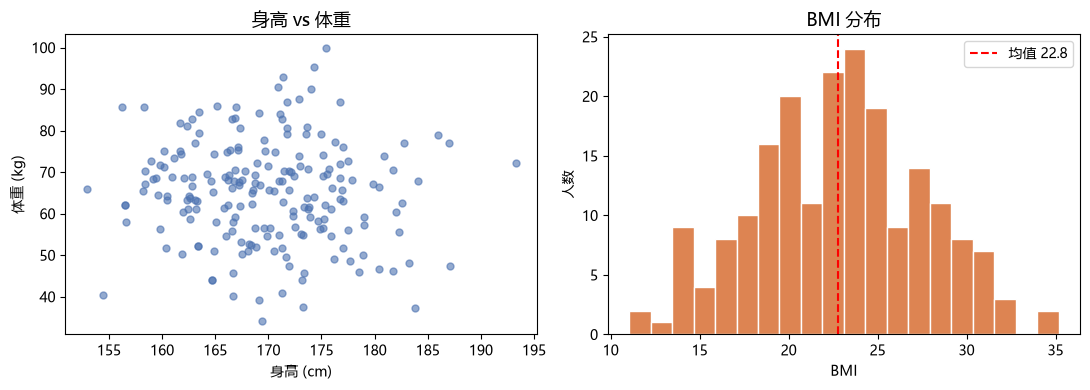

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(df["身高cm"], df["体重kg"], alpha=0.6, s=25, color="#4C72B0")
axes[0].set_title("身高 vs 体重", fontsize=13)
axes[0].set_xlabel("身高 (cm)")
axes[0].set_ylabel("体重 (kg)")

axes[1].hist(df["BMI"], bins=20, color="#DD8452", edgecolor="white")
axes[1].axvline(
    df["BMI"].mean(), color="red", linestyle="--", label=f"均值 {df['BMI'].mean():.1f}"
)
axes[1].set_title("BMI 分布", fontsize=13)
axes[1].set_xlabel("BMI")
axes[1].set_ylabel("人数")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. 自检通过了吗

- 两张图都出来了，中文标题不是方框 → **环境 OK**
- 中文变成 `□□□` → 检查 `font.sans-serif`，执行 `plt.rcParams["font.sans-serif"]` 看当前值
- 报 `ModuleNotFoundError` → 解释器选错了，或者包没装上

## 5. 接下来

阶段 1 第一课是 numpy。动手之前，先自己想一个问题：

> 已经有 `list` 了，为什么还需要 numpy 数组？

带着这个问题往下学，比背 API 有用得多。